# Семинар 2. Библиотека `CatBoost`

На этом семинаре мы рассмотрим библиотеку `CatBoost`, включая её самые мрачные и скрытые уголки, в которые до нас вряд ли кто-то заглядывал.

[Документация](https://catboost.ai/docs/en/) `CatBoost` местами противоречива: в ней есть ошибки и неточные формулировки.

При этом в документации много полезного. Основные разделы, на которые стоит обратить внимание:
* Algorithm Details, Key Features, Model Analysis — идеи работы алгоритма, его частей и методов.
* Training Parameters — описание гиперпараметров.
* Python Package — API Reference и ключ по работе с сущностями библиотеки.

А ещё у `CatBoost` есть отличный телеграм-чат @catboost_ru, в котором разработчики отвечают на вопросы пользователей.

## Подготовка

Чтобы изучить библиотеку, возьмём датасет [UCI Adult](https://archive.ics.uci.edu/dataset/2/adult).

Попробуем предсказать, будет ли годовой доход человека выше 50 тыс $ (бинарный таргет) в зависимости от его образования, семейного положения, работы и других показателей. Для удобства возьмём датасет из библиотеки `shap`, которую ты изучишь подробнее дальше на курсе.


In [ ]:
import numpy as np, pandas as pd
import shap

X, y = shap.datasets.adult()

y = pd.Series(y.astype(np.uint8))

X.info()
X.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             32561 non-null  float32
 1   Workclass       32561 non-null  int8   
 2   Education-Num   32561 non-null  float32
 3   Marital Status  32561 non-null  int8   
 4   Occupation      32561 non-null  int8   
 5   Relationship    32561 non-null  int64  
 6   Race            32561 non-null  int8   
 7   Sex             32561 non-null  int8   
 8   Capital Gain    32561 non-null  float32
 9   Capital Loss    32561 non-null  float32
 10  Hours per week  32561 non-null  float32
 11  Country         32561 non-null  int8   
dtypes: float32(5), int64(1), int8(6)
memory usage: 1.1 MB


,Age,Workclass,Education-Num,Marital Status,Occupation,Relationship,Race,Sex,Capital Gain,Capital Loss,Hours per week,Country
0,39.0,7,13.0,4,1,0,4,1,2174.0,0.0,40.0,39
1,50.0,6,13.0,2,4,4,4,1,0.0,0.0,13.0,39
2,38.0,4,9.0,0,6,0,4,1,0.0,0.0,40.0,39


In [ ]:
# Ищем категориальные признаки в данных (простая проверка)
cat_cols = []
for col in X.columns:
    if X[col].nunique() < 15:
        print(X[col].value_counts(dropna=False, normalize=True).round(2))
        X[col] = X[col].astype('category') # xgboost и LightGBM понимают, что признаки типа 'category' — категориальные
        cat_cols.append(col)

Workclass
4    0.70
6    0.08
2    0.06
0    0.06
7    0.04
5    0.03
1    0.03
8    0.00
3    0.00
Name: proportion, dtype: float64
Marital Status
2    0.46
4    0.33
0    0.14
5    0.03
6    0.03
3    0.01
1    0.00
Name: proportion, dtype: float64
Relationship
4    0.41
0    0.26
3    0.16
1    0.11
5    0.05
2    0.03
Name: proportion, dtype: float64
Race
4    0.85
2    0.10
1    0.03
0    0.01
3    0.01
Name: proportion, dtype: float64
Sex
1    0.67
0    0.33
Name: proportion, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.33, shuffle=True, random_state=911)

## Основа `CatBoost`

Как и в прошлом семинаре, начнём с базового кода.

 > **Примечание.** Некоторые пояснения, которые разбирались в прошлом семинаре (например, о преимуществе анализа «сырых» скоров перед вероятностями), будут опущены. Здесь мы подробнее остановимся на особенностях конкретной библиотеки.

### Базовый код



In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.2 MB/s eta 0:00:00


In [ ]:
cb_tr = cb.Pool(X_tr, y_tr, cat_features=cat_cols) # Несмотря на то, что CatBoost распознаёт тип 'category', он требует явного указания категориальных признаков

params = {
    'loss_function': 'Logloss',
    'learning_rate': 0.1,
    'depth': 3,
    'iterations': 200, # Количество деревьев
    'logging_level': 'Silent', # Не принтить лишние выводы

    'task_type': 'CPU', # 'CPU'/'GPU'. В CatBoost результаты обучения на cpu/gpu отличаются!
    'thread_count': 8, # Количество ядер на процессоре для распараллеливания
}

In [ ]:
import catboost as cb

In [ ]:
import catboost as cb

cb_tr = cb.Pool(X_tr, y_tr, cat_features=cat_cols) # Несмотря на то, что CatBoost распознаёт тип 'category', он требует явного указания категориальных признаков

params = {
    'loss_function': 'Logloss',
    'learning_rate': 0.1,
    'depth': 3,
    'iterations': 200, # Количество деревьев
    'logging_level': 'Silent', # Не принтить лишние выводы

    'task_type': 'CPU', # 'CPU'/'GPU'. В CatBoost результаты обучения на cpu/gpu отличаются!
    'thread_count': 8, # Количество ядер на процессоре для распараллеливания
}
model = cb.CatBoost(params)
model.fit(cb_tr)

y_prob = model.predict(X_val, prediction_type='Probability')[:, 1] # «Вероятности» — scipy.special.expit (сумма весов)
y_raw = model.predict(X_val, prediction_type='RawFormulaVal') # «Сырые» скоры — сумма весов

print('y_prob:', y_prob[:5])
print('y_raw:', y_raw[:5])

y_prob: [0.01513298 0.12676272 0.99759791 0.23297488 0.03127396]
y_raw: [-4.17563029 -1.9298903   6.02901163 -1.19158892 -3.43319611]


### Останова построения ансамбля

Рассмотрим, как в `CatBoost` реализован [Overfitting Detector](https://catboost.ai/docs/en/concepts/overfitting-detector) (`early_stopping`) — механизм раннего останова построения ансамбля.


In [ ]:
cb_val = cb.Pool(X_val, y_val, cat_features=cat_cols)

params.update({
    'od_type': 'Iter', # 'Iter' — привычный early_stopping. 'IncToDec' — можно почитать выше
    'early_stopping_rounds': 20,
    'eval_metric': 'AUC', # Здесь можно задать только одну метрику, которая используется для Overfitting Detector
    'metric_period': 20, # Выводить результат каждые 20 деревьев
    'logging_level': 'Verbose'
})

model = cb.CatBoost(params)
model.fit(cb_tr, eval_set=[cb_val])

0:	test: 0.7866995	best: 0.7866995 (0)	total: 112ms	remaining: 22.3s
20:	test: 0.9095530	best: 0.9095977 (19)	total: 1.61s	remaining: 13.7s
40:	test: 0.9158905	best: 0.9158905 (40)	total: 2.95s	remaining: 11.5s
60:	test: 0.9194497	best: 0.9194497 (60)	total: 6.26s	remaining: 14.3s
80:	test: 0.9222427	best: 0.9222427 (80)	total: 9.08s	remaining: 13.3s
100:	test: 0.9233620	best: 0.9233620 (100)	total: 10.3s	remaining: 10.1s
120:	test: 0.9264700	best: 0.9264700 (120)	total: 11.6s	remaining: 7.54s
140:	test: 0.9276428	best: 0.9276428 (140)	total: 12.7s	remaining: 5.33s
160:	test: 0.9290258	best: 0.9290258 (160)	total: 13.8s	remaining: 3.35s
180:	test: 0.9295155	best: 0.9295155 (180)	total: 14.9s	remaining: 1.57s
199:	test: 0.9299143	best: 0.9299254 (195)	total: 15.8s	remaining: 0us

bestTest = 0.9299254097
bestIteration = 195

Shrink model to first 196 iterations.


CatBoost(depth=3, early_stopping_rounds=20, eval_metric='AUC', iterations=200, learning_rate=0.1, logging_level='Verbose', loss_function='Logloss', metric_period=20, od_type='Iter', task_type='CPU', thread_count=8)

### Логирование метрик при обучении

Рассмотрим, как логировать значения нескольких метрик в процессе обучения независимо от `early_stopping`.

In [ ]:
params.update({
    'od_type': 'Iter',
    'early_stopping_rounds': 20,
    'eval_metric': 'AUC',
    'custom_metric': ['Precision:hints=skip_train~true', 'F1:hints=skip_train~true'], # Метрики для логирования. По умолчанию считаются также на трейне. Отключаем это
    'metric_period': 20,
    'logging_level': 'Verbose',
})


model = cb.CatBoost(params)
model.fit(cb_tr, eval_set=[cb_val], plot=True) # plot=True не работает в Google Colab, но в другой среде может быть удобен

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

0:	test: 0.7866995	best: 0.7866995 (0)	total: 71ms	remaining: 14.1s
20:	test: 0.9095530	best: 0.9095977 (19)	total: 1.28s	remaining: 10.9s
40:	test: 0.9158905	best: 0.9158905 (40)	total: 2.46s	remaining: 9.53s
60:	test: 0.9194497	best: 0.9194497 (60)	total: 3.9s	remaining: 8.89s
80:	test: 0.9222427	best: 0.9222427 (80)	total: 5.88s	remaining: 8.63s
100:	test: 0.9233620	best: 0.9233620 (100)	total: 7.15s	remaining: 7.01s
120:	test: 0.9264700	best: 0.9264700 (120)	total: 8.37s	remaining: 5.46s
140:	test: 0.9276428	best: 0.9276428 (140)	total: 9.74s	remaining: 4.08s
160:	test: 0.9290258	best: 0.9290258 (160)	total: 10.8s	remaining: 2.62s
180:	test: 0.9295155	best: 0.9295155 (180)	total: 11.8s	remaining: 1.24s
199:	test: 0.9299143	best: 0.9299254 (195)	total: 12.3s	remaining: 0us

bestTest = 0.9299254097
bestIteration = 195

Shrink model to first 196 iterations.


CatBoost(custom_metric=['Precision:hints=skip_train~true', 'F1:hints=skip_train~true'], depth=3, early_stopping_rounds=20, eval_metric='AUC', iterations=200, learning_rate=0.1, logging_level='Verbose', loss_function='Logloss', metric_period=20, od_type='Iter', task_type='CPU', thread_count=8)

In [ ]:
print('model.get_evals_result() keys:\t\t\t\t', model.get_evals_result().keys())
print('model.get_evals_result()["learn"] keys:\t\t\t', model.get_evals_result()['learn'].keys())
print('model.get_evals_result()["validation"] keys:\t\t', model.get_evals_result()['validation'].keys())
print('model.get_evals_result()["validation"]["F1"] len:\t', len(model.get_evals_result()['validation']['F1']))
print('model.get_evals_result()["validation"]["AUC"] len:\t', len(model.get_evals_result()['validation']['AUC']))

model.get_evals_result() keys:				 dict_keys(['learn', 'validation'])
model.get_evals_result()["learn"] keys:			 dict_keys(['Logloss'])
model.get_evals_result()["validation"] keys:		 dict_keys(['F1', 'Logloss', 'Precision', 'AUC'])
model.get_evals_result()["validation"]["F1"] len:	 11
model.get_evals_result()["validation"]["AUC"] len:	 200


#### Кастомные метрики

В `CatBoost` можно задать [кастомные метрики](https://catboost.ai/docs/en/concepts/python-usages-examples#custom-loss-function-eval-metric), которые работают по тем же принципам, что и в `LightGBM`. Единственное отличие — нужно указывать классы, а не функции. Кастомные метрики и лосс в `CatBoost` оптимизируются с помощью [Numba](https://numba.readthedocs.io/en/stable/user/5minguide.html), поэтому в примерах реализация всегда идёт через циклы, хотя иногда векторная реализация оказывается немного быстрее. Рассмотрим каждую.

Шаблон кастомной метрики в `CatBoost`:

```python
class UserDefinedMetric(object):
    def is_max_optimal(self):
        # Returns whether great values of metric are better
        pass

    def evaluate(self, approxes, target, weight):
        # Approxes is a list of indexed containers
        # (containers with only __len__ and __getitem__ defined),
        # One container per approx dimension.
        # Each container contains floats.
        # Weight is a one dimensional indexed container.
        # Target is a one dimensional indexed container.

        # Weight parameter can be None.
        # Returns pair (error, weights sum)
        pass

    def get_final_error(self, error, weight):
        # Returns final value of metric based on error and weight
        pass

```
**Важно.** Если в `CatBoost` использовать встроенный `Logloss`, то в кастомную метрику приходят именно «сырые» скоры в виде `approxes`, а не «вероятности», как в `LightGBM`. Поэтому не возникает проблема «переключения режимов» с кастомной метрики на кастомный и встроенный лосс.

Для примера реализуем кастомный `LogLoss` с использованием цикла из туториала и без него.


In [ ]:
class LoglossMetricWithFor(object):
    def get_final_error(self, error, weight):
        return error / (weight + 1e-38)

    def is_max_optimal(self):
        return False

    def evaluate(self, approxes, target, weight):
        approx = approxes[0]

        error_sum = 0.0
        weight_sum = 0.0

        for i in range(len(approx)):
            e = np.exp(approx[i])
            p = e / (1 + e)
            w = 1.0 if weight is None else weight[i]
            weight_sum += w
            error_sum += -w * (target[i] * np.log(p) + (1 - target[i]) * np.log(1 - p))

        return error_sum, weight_sum


params.update({
    'od_type': 'Iter',
    'early_stopping_rounds': 20,
    'eval_metric': LoglossMetricWithFor(),
    'custom_metric': None,
    'metric_period': 20,
    'logging_level': 'Verbose'
})

model = cb.CatBoost(params)
model.fit(cb_tr, eval_set=[cb_val])
model.fit(cb_tr, eval_set=[cb_val]) # Второй раз для того, чтобы numba «прогрелась» и можно было трезво оценить время работы

print('родной LogLoss:', model.get_evals_result()['validation']['Logloss'][-1])
print('custom LogLoss с for:', model.get_evals_result()['validation']['LoglossMetricWithFor'][-1])

0:	learn: 0.6280930	test: 0.6273293	best: 0.6273293 (0)	total: 1.89s	remaining: 6m 15s
20:	learn: 0.3409008	test: 0.3299340	best: 0.3299340 (20)	total: 2.41s	remaining: 20.5s
40:	learn: 0.3196070	test: 0.3073154	best: 0.3073154 (40)	total: 2.94s	remaining: 11.4s
60:	learn: 0.3104710	test: 0.2981086	best: 0.2981086 (60)	total: 3.45s	remaining: 7.85s
80:	learn: 0.3046676	test: 0.2919822	best: 0.2919822 (80)	total: 3.97s	remaining: 5.84s
100:	learn: 0.3014630	test: 0.2894608	best: 0.2894608 (100)	total: 4.78s	remaining: 4.69s
120:	learn: 0.2951248	test: 0.2832906	best: 0.2832906 (120)	total: 5.75s	remaining: 3.76s
140:	learn: 0.2916779	test: 0.2807142	best: 0.2807142 (140)	total: 6.68s	remaining: 2.8s
160:	learn: 0.2884552	test: 0.2780953	best: 0.2780953 (160)	total: 7.45s	remaining: 1.8s
180:	learn: 0.2865959	test: 0.2768743	best: 0.2768743 (180)	total: 8s	remaining: 840ms
199:	learn: 0.2850013	test: 0.2759089	best: 0.2759089 (199)	total: 8.47s	remaining: 0us

bestTest = 0.2759088732
bes

0:	learn: 0.6280930	test: 0.6273293	best: 0.6273293 (0)	total: 231ms	remaining: 46.1s
20:	learn: 0.3409008	test: 0.3299340	best: 0.3299340 (20)	total: 775ms	remaining: 6.61s
40:	learn: 0.3196070	test: 0.3073154	best: 0.3073154 (40)	total: 1.28s	remaining: 4.98s
60:	learn: 0.3104710	test: 0.2981086	best: 0.2981086 (60)	total: 1.81s	remaining: 4.13s
80:	learn: 0.3046676	test: 0.2919822	best: 0.2919822 (80)	total: 2.34s	remaining: 3.44s
100:	learn: 0.3014630	test: 0.2894608	best: 0.2894608 (100)	total: 2.87s	remaining: 2.81s
120:	learn: 0.2951248	test: 0.2832906	best: 0.2832906 (120)	total: 3.39s	remaining: 2.21s
140:	learn: 0.2916779	test: 0.2807142	best: 0.2807142 (140)	total: 3.92s	remaining: 1.64s
160:	learn: 0.2884552	test: 0.2780953	best: 0.2780953 (160)	total: 4.44s	remaining: 1.07s
180:	learn: 0.2865959	test: 0.2768743	best: 0.2768743 (180)	total: 4.99s	remaining: 523ms
199:	learn: 0.2850013	test: 0.2759089	best: 0.2759089 (199)	total: 5.47s	remaining: 0us

bestTest = 0.2759088732

In [ ]:
class LoglossMetric(object):
    def get_final_error(self, error, weight):
        return error / (weight + 1e-38)

    def is_max_optimal(self):
        return False

    def evaluate(self, approxes, target, weight):
        approx = np.array(approxes[0]) # На всякий случай. Нам не гарантируют, что это np.array :)

        if weight is None:
            weight = np.ones_like(approx)
        p = 1 / (1 + np.exp(-approx))
        errors = -weight * (target * np.log(p) + (1 - target) * np.log(1 - p))
        return errors.sum(), weight.sum()

params.update({
    'od_type': 'Iter',
    'early_stopping_rounds': 20,
    'eval_metric': LoglossMetric(),
    'custom_metric': None,
    'metric_period': 20,
    'logging_level': 'Verbose'
})

model = cb.CatBoost(params)
model.fit(cb_tr, eval_set=[cb_val])

print('родной LogLoss:', model.get_evals_result()['validation']['Logloss'][-1])
print('custom LogLoss без for:', model.get_evals_result()['validation']['LoglossMetric'][-1])

/usr/local/lib/python3.12/dist-packages/catboost/core.py:1824: UserWarning: Failed to optimize method "evaluate" in the passed object:
Failed in nopython mode pipeline (step: nopython frontend)
No implementation of function Function(<built-in function array>) found for signature:
 
 >>> array(array(float64, 1d, C))
 
There are 2 candidate implementations:
  - Of which 2 did not match due to:
  Overload in function 'impl_np_array': File: numba/np/arrayobj.py: Line 5432.
    With argument(s): '(array(float64, 1d, C))':
   Rejected as the implementation raised a specific error:
     TypingError: Failed in nopython mode pipeline (step: nopython frontend)
   No implementation of function Function(<intrinsic np_array>) found for signature:
    
    >>> np_array(array(float64, 1d, C), none)
    
   There are 2 candidate implementations:
         - Of which 2 did not match due to:
         Intrinsic in function 'np_array': File: numba/np/arrayobj.py: Line 5406.
           With argument(s): '(a

0:	learn: 0.6280930	test: 0.6273293	best: 0.6273293 (0)	total: 179ms	remaining: 35.7s
20:	learn: 0.3409008	test: 0.3299340	best: 0.3299340 (20)	total: 696ms	remaining: 5.93s
40:	learn: 0.3196070	test: 0.3073154	best: 0.3073154 (40)	total: 1.22s	remaining: 4.75s
60:	learn: 0.3104710	test: 0.2981086	best: 0.2981086 (60)	total: 1.75s	remaining: 3.98s
80:	learn: 0.3046676	test: 0.2919822	best: 0.2919822 (80)	total: 2.26s	remaining: 3.33s
100:	learn: 0.3014630	test: 0.2894608	best: 0.2894608 (100)	total: 2.78s	remaining: 2.72s
120:	learn: 0.2951248	test: 0.2832906	best: 0.2832906 (120)	total: 3.42s	remaining: 2.23s
140:	learn: 0.2916779	test: 0.2807142	best: 0.2807142 (140)	total: 4.4s	remaining: 1.84s
160:	learn: 0.2884552	test: 0.2780953	best: 0.2780953 (160)	total: 5.35s	remaining: 1.3s
180:	learn: 0.2865959	test: 0.2768743	best: 0.2768743 (180)	total: 6.32s	remaining: 664ms
199:	learn: 0.2850013	test: 0.2759089	best: 0.2759089 (199)	total: 6.81s	remaining: 0us

bestTest = 0.2759088732
b

Что мы видим:
* `numba` предупреждает, что не может ускорить код.
* Встроенный и кастомный лоссы идентичны.

В Google Colab данные отличаются для разных запусков, поэтому та или иная реализация может быть быстрее. Однако на практике используй ту, которая тебе нравится.

#### Задание 1 [3 балла]

Реализуй кастомную метрику F1, используя циклы. В данном задании игнорируй веса (в методе `evaluate` возвращай `f1_score, 1`). Принимай на вход порог бинаризации. Проверь свою метрику на текущем датасете.



In [ ]:
class F1Metric(object):
    def get_final_error(self, error, weight):
        return error

    def is_max_optimal(self):
        return True

    def evaluate(self, approxes, target, weight):
        approx = np.array(approxes[0]) # На всякий случай. Нам не гарантируют, что это np.array :)

        tp = fp = fn = 0
        for i, pred in enumerate(approx):
            e = np.exp(approx)
            prob = e/(1 + e)
            y_pred = 1 if (prob > 0.5).any() else 0
            y_true = target[i]

            if y_true == 1 and y_pred == 1:
                tp += 1
            elif y_true == 0 and y_pred == 1:
                fp += 1
            elif y_true == 1 and y_pred == 0:
                fn += 1

        precision = tp/(tp + fp)
        recall = tp/(tp + fn)

        f1_score = 2 * precision * recall / (precision + recall)

        return f1_score, 1

params.update({
    'od_type': 'Iter',
    'early_stopping_rounds': 20,
    'eval_metric': F1Metric(),
    'custom_metric': None,
    'metric_period': 20,
    'logging_level': 'Verbose'
})

model = cb.CatBoost(params)
model.fit(cb_tr, eval_set=[cb_val])

print('custom F1-Score for:', model.get_evals_result()['validation']['F1Metric'][-1])

/usr/local/lib/python3.12/dist-packages/catboost/core.py:1824: UserWarning: Failed to optimize method "evaluate" in the passed object:
Failed in nopython mode pipeline (step: nopython frontend)
No implementation of function Function(<built-in function array>) found for signature:
 
 >>> array(array(float64, 1d, C))
 
There are 2 candidate implementations:
     - Of which 2 did not match due to:
     Overload in function 'impl_np_array': File: numba/np/arrayobj.py: Line 5432.
       With argument(s): '(array(float64, 1d, C))':
      Rejected as the implementation raised a specific error:
        TypingError: Failed in nopython mode pipeline (step: nopython frontend)
      No implementation of function Function(<intrinsic np_array>) found for signature:
       
       >>> np_array(array(float64, 1d, C), none)
       
      There are 2 candidate implementations:
            - Of which 2 did not match due to:
            Intrinsic in function 'np_array': File: numba/np/arrayobj.py: Line 54

0:	learn: 0.3908088	test: 0.3827226	best: 0.3827226 (0)	total: 7.31s	remaining: 24m 14s


CatBoostError: catboost/python-package/catboost/helpers.cpp:58: Traceback (most recent call last):
  File "_catboost.pyx", line 1614, in _catboost._MetricEval
  File "_catboost.pyx", line 1835, in _catboost._cpu_jit_method_wrap.new_method
  File "/tmp/ipykernel_19634/1686561985.py", line 15, in evaluate
    y_pred = 1 if (prob > 0.5).any() else 0
                  ^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py", line 58, in _any
    def _any(a, axis=None, dtype=None, out=None, keepdims=False, *, where=True):
    
KeyboardInterrupt


### Веса на объектах

Аналогично `LightGBM` веса на объектах в `CatBoost` можно задать с помощью привычных гиперпараметров (`class_weights`, `auto_class_weights`, `scale_pos_weight`) или явно задать вектора весов в `cb.Pool` (`cb.Pool` → аргумент `weight`).

In [ ]:
params.update({
    # 'class_weights': [0.3, 1.2], # Веса класса 0, веса класса 1. Рекомендуется использовать, когда классов больше одного
    'auto_class_weights': 'Balanced', # Есть ещё 'SqrtBalanced'
    # 'scale_pos_weight': 4.33, # Аналогично LightGBM. Вместе эти параметры использовать нельзя
})
params['eval_metric'] = 'AUC'

model = cb.CatBoost(params)
model.fit(cb_tr, eval_set=[cb_val])

0:	test: 0.8491894	best: 0.8491894 (0)	total: 28.6ms	remaining: 5.7s
20:	test: 0.9078625	best: 0.9078625 (20)	total: 556ms	remaining: 4.74s
40:	test: 0.9154468	best: 0.9154468 (40)	total: 1.07s	remaining: 4.13s
60:	test: 0.9173708	best: 0.9173708 (60)	total: 1.57s	remaining: 3.59s
80:	test: 0.9203071	best: 0.9203071 (80)	total: 2.06s	remaining: 3.03s
100:	test: 0.9216839	best: 0.9216839 (100)	total: 2.61s	remaining: 2.56s
120:	test: 0.9239921	best: 0.9239921 (120)	total: 3.14s	remaining: 2.05s
140:	test: 0.9264364	best: 0.9264364 (140)	total: 3.69s	remaining: 1.54s
160:	test: 0.9272362	best: 0.9272362 (160)	total: 4.2s	remaining: 1.02s
180:	test: 0.9279097	best: 0.9279214 (179)	total: 4.74s	remaining: 498ms
199:	test: 0.9281902	best: 0.9282254 (198)	total: 5.23s	remaining: 0us

bestTest = 0.9282253565
bestIteration = 198

Shrink model to first 199 iterations.


CatBoost(auto_class_weights='Balanced', custom_metric=None, depth=3, early_stopping_rounds=20, eval_metric='AUC', iterations=200, learning_rate=0.1, logging_level='Verbose', loss_function='Logloss', metric_period=20, od_type='Iter', task_type='CPU', thread_count=8)

In [ ]:
# del params['scale_pos_weight']
# del params['auto_class_weights']
# del params['class_weights']


w = np.abs(np.random.randn(X_tr.shape[0]))
w = X_tr.shape[0] * w / w.sum()
cb_tr = cb.Pool(X_tr, y_tr, weight=w, cat_features=cat_cols)

model = cb.CatBoost(params)
model.fit(cb_tr, eval_set=[cb_val])

0:	test: 0.7893283	best: 0.7893283 (0)	total: 84.3ms	remaining: 16.8s
20:	test: 0.9052446	best: 0.9052446 (20)	total: 1.09s	remaining: 9.27s
40:	test: 0.9131954	best: 0.9131954 (40)	total: 2.13s	remaining: 8.27s
60:	test: 0.9169991	best: 0.9169991 (60)	total: 3.22s	remaining: 7.35s
80:	test: 0.9192901	best: 0.9192901 (80)	total: 3.99s	remaining: 5.86s
100:	test: 0.9211597	best: 0.9211597 (100)	total: 4.58s	remaining: 4.49s
120:	test: 0.9246032	best: 0.9246032 (120)	total: 5.75s	remaining: 3.76s
140:	test: 0.9259234	best: 0.9259234 (140)	total: 7.02s	remaining: 2.94s
160:	test: 0.9264606	best: 0.9265211 (159)	total: 7.61s	remaining: 1.84s
180:	test: 0.9269770	best: 0.9269770 (180)	total: 8.14s	remaining: 855ms
199:	test: 0.9271725	best: 0.9272102 (192)	total: 8.65s	remaining: 0us

bestTest = 0.927210243
bestIteration = 192

Shrink model to first 193 iterations.


CatBoost(custom_metric=None, depth=3, early_stopping_rounds=20, eval_metric='AUC', iterations=200, learning_rate=0.1, logging_level='Verbose', loss_function='Logloss', metric_period=20, od_type='Iter', task_type='CPU', thread_count=8)

### Интерпретация

Рассмотрим встроенные средства интерпретации модели.

Про метод `shap` сейчас говорить не будем, его рассмотрим позже на курсе.

В `LightGBM` важнейший источник инсайтов о модели — ансамбль `model.trees_to_dataframe`, сохранённый в виде датафрейма. В `CatBoost` нет аналогичного метода, но можно хитрым способом получить информацию в виде словаря:
1. Сохранить модель в формате JSON.
2. Загрузить её обратно.
3. Попробовать спарсить результат.

Подробнее изучить тему можно [здесь](https://github.com/catboost/tutorials/blob/master/model_analysis/model_export_as_json_tutorial.ipynb).

In [ ]:
import json

model.save_model('my_model', format='json')

with open('my_model', 'r') as f:
    my_model = json.load(f)

print('my_model keys:\t\t\t\t', my_model.keys())
print('my_model["oblivious_trees"] len:\t', len(my_model['oblivious_trees']))
print('my_model["oblivious_trees"][0] keys:\t', my_model['oblivious_trees'][0].keys())
print('\nmy_model["oblivious_trees"][0]["splits"]:')
pd.DataFrame(my_model['oblivious_trees'][0]['splits'])

my_model keys:				 dict_keys(['ctr_data', 'features_info', 'model_info', 'oblivious_trees', 'scale_and_bias'])
my_model["oblivious_trees"] len:	 193
my_model["oblivious_trees"][0] keys:	 dict_keys(['leaf_values', 'leaf_weights', 'splits'])

my_model["oblivious_trees"][0]["splits"]:


,border,float_feature_index,split_index,split_type
0,4898.0,3,59,FloatFeature
1,10.5,1,35,FloatFeature
2,33.5,0,7,FloatFeature


Также в `CatBoost` можно рисовать построенные деревья с помощью библиотеки `graphviz`.

Подробнее изучить тему можно [здесь](https://github.com/catboost/tutorials/blob/master/model_analysis/visualize_decision_trees_tutorial.ipynb).




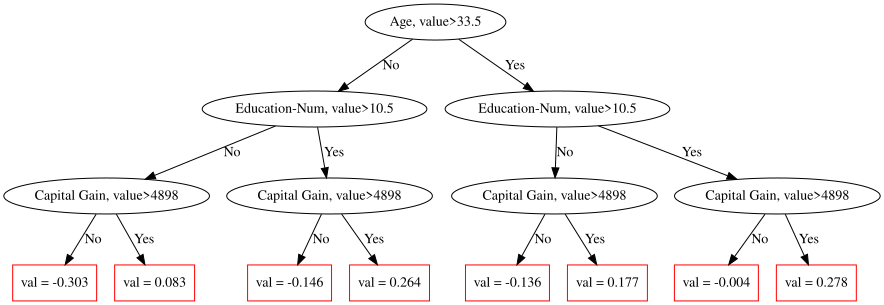

In [ ]:
model.plot_tree(tree_idx=0, pool=cb_tr)

Из уже обученной модели методом `model.get_feature_importance()` `CatBoost` автоматически считывает важность признаков:
* по их влиянию на изменение предсказаний или лосса,
* взаимодействий между признаками.

Подробнее изучить тему можно [здесь](https://catboost.ai/docs/en/concepts/model-analysis).


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

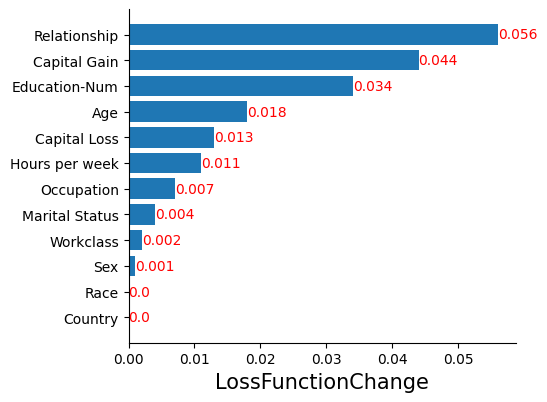

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


def plot_catboost_importance(model, features, pool=None, importance_type='FeatureImportance', top_k=20, round_to=None):
    '''
    importance_type:
        - 'LossFunctionChange'
        - 'PredictionValuesChange'

    round_to: int — округление чисел на графике до round_to после запятой
    '''
    imps = model.get_feature_importance(data=pool, type=importance_type)

    idx = np.argsort(imps)
    sorted_imps = imps[idx][::-1][:top_k][::-1]
    sorted_features = features[idx][::-1][:top_k][::-1]
    if round_to == 0:
        sorted_imps = sorted_imps.astype(int)
    elif round_to is not None:
        sorted_imps = np.round(sorted_imps, round_to)

    bar_container = plt.barh(width=sorted_imps, y=sorted_features)
    plt.bar_label(bar_container, sorted_imps, color='red')
    plt.gcf().set_size_inches(5, top_k/6 + 1)
    plt.xlabel(importance_type, fontsize=15)
    sns.despine()


plot_catboost_importance(model, X_tr.columns, pool=cb_tr, importance_type='LossFunctionChange', round_to=3)

Взаимодействия признаков:

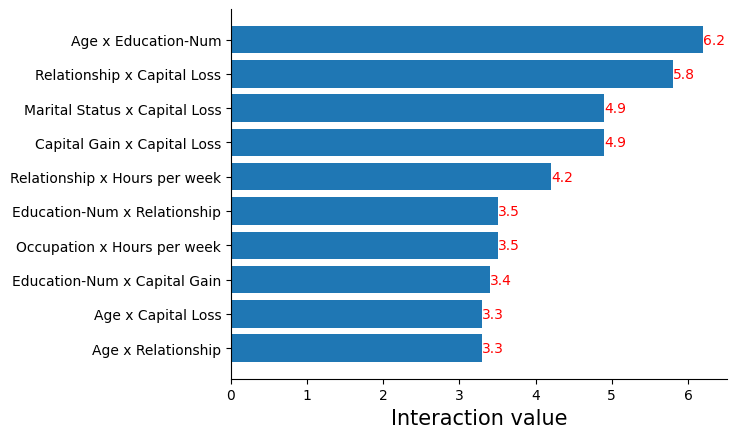

In [ ]:
model.get_feature_importance(type='Interaction')

def plot_feature_interactions(model, features, top_k=20, round_to=None):
    interactions = model.get_feature_importance(type='Interaction')
    pair_idx = interactions[:, :2].astype(int)
    feature_pairs = np.array(features)[pair_idx]
    feature_pairs_str = feature_pairs[:, 0] + ' x ' + feature_pairs[:, 1]
    interaction_values = interactions[:top_k, -1][::-1]
    if round_to == 0:
        interaction_values = interaction_values.astype(int)
    elif round_to is not None:
        interaction_values = np.round(interaction_values, round_to)

    bar_container = plt.barh(y=feature_pairs_str[:top_k][::-1], width=interaction_values)
    plt.bar_label(bar_container, interaction_values, color='red')
    plt.xlabel('Interaction value', fontsize=15)
    sns.despine()

plot_feature_interactions(model, X_tr.columns, top_k=10, round_to=1)

Ещё из построенной модели можно вывести статистики по отдельным признакам методом `model.calc_feature_statistics`.

Поскольку Google Colab не отображает графики `CatBoost`, итоговую статистику в формате графика и описание метода можно найти [здесь](https://catboost.ai/docs/en/concepts/python-reference_catboost_calc_feature_statistics).


In [ ]:
 # model.calc_feature_statistics(cb_tr, feature='Age', plot=True, prediction_type='RawFormulaVal') # Не рисует!

## Ключевые гиперпараметры

Мы не будем повторять информацию из семинара по `LightGBM`, а сразу подробно разберём особенности `CatBoost`.

### Базовые гиперпараметры
- `eta` — темп обучения (как и в `LightGBM`), самый важный гиперпараметр.
- `depth` (глубина ленивых деревьев) — критерий останова для построения конкретного дерева.
- `min_data_in_leaf` — в вершинах с меньшим количеством объектов сплиты не делаются.
- `score_function` — выбор скорера сплитов (= меры похожести на антиградиент).

  Варианты: `L2`, `Cosine`, `NewtonL2`, `NewtonCosine`, `Newton`. Приставка `Newton` означает, во время скоринга «временные веса» будут считаться по формуле приближения лосса до второго члена (с «гессианами»), а без неё — только через «градиенты» (это быстрее).
  
  Если время обучения не сильно увеличивается, можно ставить Newton-варианты, а `L2` или `Cosine` рекомендуется перебирать в зависимости от задачи.
- `leaf_estimation_method` — метод подсчёта весов в «конечных листьях».

  Варианты: `Newton` (точнее, но работает дольше), `Exact` (выходит за рамки данного семинара), `Gradient`.
- `leaf_estimation_iterations` — количество «итераций спуска» для подсчёта весов в «конечных листьях».

  Если установить значение больше единицы, алгоритм выполнит несколько итераций с начальным приближением, рассчитанным по указанной формуле.
- `l2_leaf_reg` — L2-регуляризация в листьях (как и в `LightGBM`).
- `one_hot_max_size` — основной параметр для категориальных признаков (обычно подбирается в диапазоне `[2, 8]`).
- `max_ctr_complexity` = 4 — максимальное количество признаков, которые могут быть соединены в один.

  На уровне глубины построения дерева $d$ `CatBoost` может использовать всевозможные комбинации признаков размера `max_ctr_complexity`, которые были выбраны для сплитов ранее.
  
  В некоторых случаях этот гиперпараметр тормозит алгоритм, но привносит новые комбинации признаков, которые потенциально могут улучшить качество.

Подробнее изучить тему можно здесь:

* [Базовые гиперпараметры](https://catboost.ai/docs/en/references/training-parameters/).
* [Настройки квантования](https://catboost.ai/docs/en/concepts/quantization).
* [Параметры преобразования категориальных признаков в числовые](https://catboost.ai/docs/en/concepts/algorithm-main-stages_cat-to-numberic).
* [Параметр `max_ctr_complexity`](https://arxiv.org/pdf/1706.09516).








###Задание 2 [1 балл]

В качестве упражнения поработай с гиперпараметрами `leaf_estimation_method` и `leaf_estimation_iterations` и посмотри, как различные значения влияют на качество и скорость обучения. Рассмотри методы `Newton`, `Gradient` и `leaf_estimation_iterations` из множества `[1, 5, 10]`.

Замерить время работы можно, например, так:
```python
import time

start_time = time.time()
model.fit(...)
print('fit time:', time.time() - start_time, 'sec')
```


In [ ]:
from sklearn.metrics import roc_auc_score

In [ ]:
import time

leaf_estimation_methods = ['Newton', 'Gradient']
leaf_estimation_iterations = [1, 5, 10]
for leaf_estimation_method in leaf_estimation_methods:
    for leaf_estimation_iteration in leaf_estimation_iterations:
        p = params.copy()
        p.update({
            'leaf_estimation_method': leaf_estimation_method,
            'leaf_estimation_iterations': leaf_estimation_iteration,
            'logging_level': 'Silent',
            'od_type': 'Iter',
            'early_stopping_rounds': 30,
            'eval_metric': 'AUC',
        })

        m = cb.CatBoost(p)

        t0 = time.time()
        m.fit(cb_tr, eval_set=[cb_val])
        t1 = time.time()

        dt = t1 - t0

        auc = roc_auc_score(y_val, m.predict(X_val, prediction_type='Probability')[:, 1])
        print(leaf_estimation_method, leaf_estimation_iteration, dt, auc)

Newton 1 2.2856297492980957 0.9247556198927633


Newton 5 4.5953943729400635 0.9268262347455534


Newton 10 6.80591893196106 0.9272102429939767


Gradient 1 2.07621693611145 0.9096259202140111


Gradient 5 5.0945634841918945 0.9224725912644582


Gradient 10 5.928826570510864 0.9251978010404391


### Ordered-режим (в сравнении с `LightGBM`)

Посмотрим, насколько быстро работает «суперчестная» версия `CatBoost`, предназначенная для малых выборок. Мы умышленно не сравниваем качество Ordered- и Plain-режимов, поскольку честная проверка требует много времени на полноценный подбор оптимальных гиперпараметров для каждого из них (хотя качество режимов примерно одинаковое). Если у тебя маленький объём выборки, стоит попробовать оба и использовать наилучший.

In [ ]:
from time import time as tm
from tqdm import tqdm
from sklearn.datasets import make_classification
import gc
import lightgbm as lgb


def make_boosting_test(n_trees):
    N = int(1e6)
    n_features = 50
    n_cat_features = 20
    X_dummy, y_dummy = make_classification(N, n_features, n_informative=n_features, n_redundant=0, n_repeated=0, random_state=911)

    cat_features = [f'cat_{i}' for i in range(n_cat_features)]
    X_cat = np.random.choice(['A', 'B', 'C', 'D', 'E', 'F', 'G'], p=[0.02, 0.2, 0.2, 0.1, 0.08, 0.2, 0.2], size=(N, n_cat_features))
    X_cat = pd.DataFrame(X_cat, dtype='category', columns=cat_features)

    X_dummy = pd.DataFrame(X_dummy, dtype=np.float32, columns=[f'num_{i}' for i in range(n_features)])
    X_dummy = pd.concat([X_dummy, X_cat], axis=1, sort=False)

    sizes = [10_000, 50_000, 100_000, 200_000, 500_000, 1_000_000]

    time_plain = []
    time_plain_gpu = []
    time_ordered = []
    time_ordered_gpu = []
    time_lgb_cpu = []
    time_lgb_gpu = []

    for size in tqdm(sizes):
        params = {
            'thread_count': 16,
            'logging_level': 'Silent',
            'task_type': 'CPU',
            'random_seed': 911,
            'iterations': n_trees
        }
        data = cb.Pool(X_dummy.iloc[:size], label=y_dummy[:size], cat_features=cat_features)
        data.quantize()

        # Plain CPU
        gc.collect()
        model = cb.CatBoost(params)
        stm = tm()
        model = model.fit(data)
        time_plain.append(tm() - stm)

        # Plain GPU
        gc.collect()
        params.update({'task_type': 'GPU'})
        model = cb.CatBoost(params)
        stm = tm()
        model = model.fit(data)
        time_plain_gpu.append(tm() - stm)

        # Ordered CPU
        if size < 300_000:
            gc.collect()
            params.update({'task_type': 'CPU', 'boosting_type': 'Ordered'})
            model = cb.CatBoost(params)
            stm = tm()
            model = model.fit(data)
            time_ordered.append(tm() - stm)

        # Ordered CPU
        gc.collect()
        params.update({'task_type': 'GPU', 'boosting_type': 'Ordered'})
        model = cb.CatBoost(params)
        stm = tm()
        model = model.fit(data)
        time_ordered_gpu.append(tm() - stm)

        # LightGBM CPU
        del data
        data = lgb.Dataset(X_dummy[:size], label=y_dummy[:size])
        data.construct()

        gc.collect()
        params = {'nthread': 16, 'verbose': -1, 'seed': 911}
        stm = tm()
        model = lgb.train(params, data, num_boost_round=n_trees)
        time_lgb_cpu.append(tm() - stm)

        # LightGBM GPU
        gc.collect()
        params = {'device': 'gpu', 'verbose': -1, 'seed': 911}
        stm = tm()
        model = lgb.train(params, data, num_boost_round=n_trees)
        time_lgb_gpu.append(tm() - stm)

    return sizes, time_plain, time_plain_gpu, time_ordered, time_ordered_gpu, time_lgb_cpu, time_lgb_gpu

sizes, time_plain, time_plain_gpu, time_ordered, time_ordered_gpu, time_lgb_cpu, time_lgb_gpu = make_boosting_test(n_trees=100)

100%|██████████| 6/6 [09:45<00:00, 97.56s/it] 


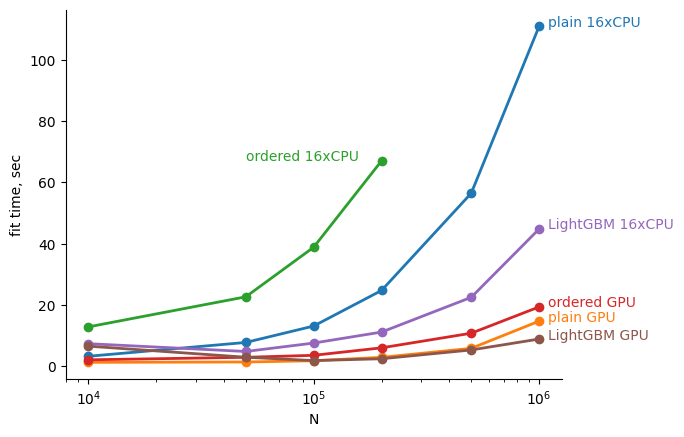

In [ ]:
p = plt.plot(sizes, time_plain, lw=2, marker='o', label='plain 16xCPU')
plt.annotate('plain 16xCPU', (sizes[-1] + 1e5, time_plain[-1]), color=p[0].get_color())
p = plt.plot(sizes, time_plain_gpu, lw=2, marker='o', label='plain GPU')
plt.annotate('plain GPU', (sizes[-1] + 1e5, time_plain_gpu[-1]), color=p[0].get_color())
p = plt.plot(sizes[:4], time_ordered, lw=2, marker='o', label='ordered 16xCPU')
plt.annotate('ordered 16xCPU', (sizes[1], time_ordered[-1]), color=p[0].get_color())
p = plt.plot(sizes, time_ordered_gpu, lw=2, marker='o', label='ordered GPU')
plt.annotate('ordered GPU', (sizes[-1] + 1e5, time_ordered_gpu[-1]), color=p[0].get_color())
p = plt.plot(sizes, time_lgb_cpu, lw=2, marker='o', label='LightGBM 16xCPU')
plt.annotate('LightGBM 16xCPU', (sizes[-1] + 1e5, time_lgb_cpu[-1]), color=p[0].get_color())
p = plt.plot(sizes, time_lgb_gpu, lw=2, marker='o', label='LightGBM GPU')
plt.annotate('LightGBM GPU', (sizes[-1] + 1e5, time_lgb_gpu[-1]), color=p[0].get_color())
plt.xscale('log')
plt.xlabel('N')
plt.ylabel('fit time, sec')
sns.despine();

Подведём итог. Ordered-режим на CPU неконкурентоспособен, но на GPU показывает себя весьма достойно. По опыту режим стоит использовать только на малых выборках (<10k объектов) и не ждать от него чуда.

 > **Примечание.** По возможности рекомендуется использовать `CatBoost` на GPU, но помни, что результаты работы будут отличаться.

Про способы ускорения можно почитать в разделе [Speeding up training](https://catboost.ai/docs/en/concepts/speed-up-training).

Сравнивая Ordered-режим с `LightGBM`, можно сказать следующее:

* Чем больше категориальных признаков, тем сильнее `CatBoost` будет проигрывать в скорости.
* Чем больше категориальных признаков, тем сильнее желание использовать библиотеку для более «качественной» обработки.

Мы специально опускаем сравнение качества, поскольку сравнение на одном конкретном датасете ничего не даст. У каждого из алгоритмов есть задачи, где он будет обходить конкурента, поэтому при выборе лучше опираться на количество и качество категориальных признаков.


### Аргумент `has_time`

Если у нас есть колонка, которая может задавать порядок на объектах (например, время, дата или ID), рекомендуется попробовать поставить `has_time=True` и задать в `cb.Pool` для обучения аргумент `timestamp=time_col`.

В таком случае `CatBoost` не будет генерировать случайные перестановки объектов, а будет использовать только порядок, индуцируемый колонкой `time_col`.

Подход не всегда работает эффективно или быстрее, чем в случае с перестановками. Однако бывают задачи, в которых этот параметр может внести существенный вклад в качество решения (например, в задачах на временные ряды).





### Семплинг объектов и признаков

`CatBoost` поддерживает только семплирование признаков на каждый новый уровень глубины — за это отвечает гиперпараметр `rsm`. Например, `rsm=0.8` означает:
* для выбора сплита в корне будут использоваться случайные 80% признаков;
* для выбора сплита на следующем уровне глубины — 80% от имеющихся и так далее.

Однако есть вероятность, что это не так, и на каждый уровень глубины будет выбираться 80% случайных признаков из изначального множества, но каждый раз — разные. На это указывает следующая строчка в документации:

> The percentage of features to use at each split selection, when features are selected over again at random («Доля признаков, используемых для каждого выбора сплита, когда признаки выбираются снова случайным образом»).

Для семплирования объектов в `CatBoost` применяются:
- `bootstrap_type` = `Bernoulli` — случайное семплирование объектов.
    - `subsample` = 0,9 — доля объектов.
    - `sampling_frequency` = `PerTree` (на каждое дерево) или `PerLevel` (на каждый уровень глубины).
- `bootstrap_type` = `MVS` — алгоритм, который используется по умолчанию для большинства задач.
  Он семплирует объекты пропорционально величине $\sqrt{g_i^2 + mvs\_{reg} ⋅h_i^2}$, это что-то вроде регуляризованной ошибки на объекте. Эту схему можно рассматривать как улучшенный аналог GOSS. Подробнее можно почитать в [статье](https://arxiv.org/pdf/1910.13204).
    - `mvs_reg` (подберётся автоматически, не нужно менять).
    - `subsample` и `sampling_frequency` (необходимо настроить).
- `bootstrap_type` = `Poisson` — выходит за рамки данного семинара.
- `bootstrap_type` = `Bayesian` + `bagging_temperature` — выходит за рамки данного семинара.



In [ ]:
from time import time as tm
from tqdm import tqdm
from sklearn.datasets import make_classification
import gc

def make_subsample_test(n_trees):
    N = int(1e6)
    n_features = 100
    X_dummy, y_dummy = make_classification(N, n_features, n_informative=n_features, n_redundant=0, n_repeated=0, random_state=911)

    sizes = [10_000, 50_000, 100_000, 200_000, 1_000_000]

    time_plain = []
    time_bernoulli_06 = []
    time_bernoulli_03 = []
    time_mvs_06 = []
    time_mvs_03 = []

    for size in tqdm(sizes):
        params = {
            'thread_count': 16,
            'logging_level': 'Silent',
            'task_type': 'CPU',
            'random_seed': 911,
            'iterations': n_trees
        }
        data = cb.Pool(X_dummy[:size], label=y_dummy[:size])
        data.quantize()

        # Plain CPU
        gc.collect()
        params.update({'bootstrap_type': 'No'})
        model = cb.CatBoost(params)
        stm = tm()
        model = model.fit(data)
        time_plain.append(tm() - stm)

        # Bernoulli 0.6
        gc.collect()
        params.update({'bootstrap_type': 'Bernoulli', 'subsample': 0.6, 'sampling_frequency': 'PerTree'})
        model = cb.CatBoost(params)
        stm = tm()
        model = model.fit(data)
        time_bernoulli_06.append(tm() - stm)

        # Bernoulli 0.3
        gc.collect()
        params.update({'bootstrap_type': 'Bernoulli', 'subsample': 0.3, 'sampling_frequency': 'PerTree'})
        model = cb.CatBoost(params)
        stm = tm()
        model = model.fit(data)
        time_bernoulli_03.append(tm() - stm)

        # MVS 0.6
        gc.collect()
        params.update({'bootstrap_type': 'MVS', 'subsample': 0.6, 'sampling_frequency': 'PerTree'})
        model = cb.CatBoost(params)
        stm = tm()
        model = model.fit(data)
        time_mvs_06.append(tm() - stm)

        # MVS 0.3
        gc.collect()
        params.update({'bootstrap_type': 'MVS', 'subsample': 0.3, 'sampling_frequency': 'PerTree'})
        model = cb.CatBoost(params)
        stm = tm()
        model = model.fit(data)
        time_mvs_03.append(tm() - stm)

    return sizes, time_plain, time_bernoulli_06, time_bernoulli_03, time_mvs_06, time_mvs_03

sizes, time_plain, time_bernoulli_06, time_bernoulli_03, time_mvs_06, time_mvs_03 = make_subsample_test(n_trees=100)

100%|██████████| 5/5 [05:16<00:00, 63.28s/it]


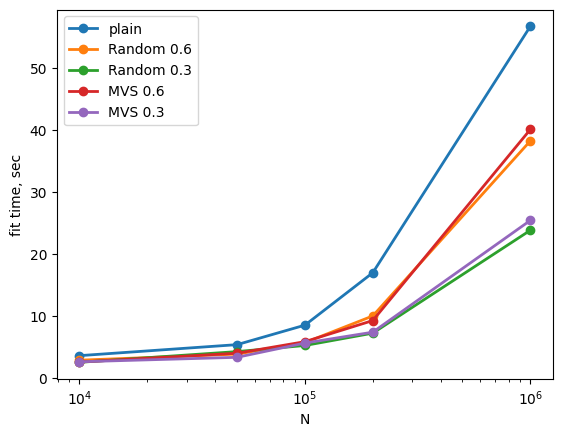

In [ ]:
plt.plot(sizes, time_plain, lw=2, marker='o', label='plain')
plt.plot(sizes, time_bernoulli_06, lw=2, marker='o', label='Random 0.6')
plt.plot(sizes, time_bernoulli_03, lw=2, marker='o', label='Random 0.3')
plt.plot(sizes, time_mvs_06, lw=2, marker='o', label='MVS 0.6')
plt.plot(sizes, time_mvs_03, lw=2, marker='o', label='MVS 0.3')
plt.xscale('log')
plt.xlabel('N')
plt.ylabel('fit time, sec')
plt.legend();

В отличие от `LightGBM`, схемы семплинга в `CatBoost` делают свою работу так, как от них ожидаешь. Стоит отметить, что на GPU нужно быть внимательнее: MVS-семплинг может быть непредсказуемым и замедлять работу алгоритма.

<!-- Видим, что в отличие от LightGBM, схемы сэмплинга в CatBoost делают свою работу так, как от них ожидаешь. Стоит отметить, что на GPU поведение MVS сэмплинга может быть довольно странным и замедлять работу алгоритма, опасайтесь!   -->

### Предварительный биннинг (квантизация признаков и таргета)

Если в `LightGBM` мы контролировали только количество бинов для предварительной квантизации признаков, то в `CatBoost` дополнительно можно контролировать «схему» квантизации. Ещё в `CatBoost` можно выбрать разные схемы для квантизации числовых и категориальных признаков, а также вспомогательной квантизации таргета для подсчёта TS.
  
Кратко рассмотрим основные схемы квантизации числовых признаков.
- `Median` — делит данные так, чтобы в каждом бине было примерно одинаковое количество объектов (аналог схемы в `LightGBM`).
- `Uniform` — разбивает отрезок `[min_feature_val, max_feature_val]` на равные части.
- `GreedyLogSum` — максимизация выражения $\sum_{i \in bin} log(weight)$, где $weight$ — the number of times an object in the bucket is repeated, что непросто трактуется. Это схема по умолчанию для числовых признаков.
 > **Примечание.** Здесь и дальше при использовании `CatBoost` мы сталкиваемся с побочным эффектом — работой с её документацией. Местами она усложняет понимание многочисленными опечатками, ошибками и неясными формулировкам.

 Описание схем можно подробнее изучить [здесь](https://catboost.ai/docs/en/concepts/quantization).

Чтобы выбрать схему квантизации для числовых признаков, нужно задать параметры `feature_border_type` и `border_count`. О квантизации категориальных признаков и таргета мы поговорим в следующем блоке.


### Кодирование категориальных признаков (CTR Settings)


> **Target Statistics** — некая функция, которая использует информацию о значениях категориального признака и таргете объекта, чтобы присвоить ему какое-то число вместо значения категории. Сплит для такого категориального признака в дальнейшем будет трактоваться как числовой.

Эта терминология взята из оригинальной статьи, но в документации библиотеки решили вместо термина TS использовать термин CTR (Click Through Rate). Не путайся, это одно и то же.

Алгоритм преобразования категориального признака в TS:

1. Если у признака меньше `one_hot_max_size` уникальных значений, мы не считаем для него TS (CTR). Иначе переходим к пункту 2.
2. Если мы решаем задачу регрессии, нужно квантизовать таргет.
3. Для каждой из перестановок $\sigma_i$ считается $f_{TS_i}$ по схеме, заданной параметром `simple_ctr`.
4. Полученные $f_{TS_i}$ тоже квантизуются и далее используются как числовые признаки.

О настройках в пунктах 2 и 4 поговорим позже. Подробнее изучить схемы преобразования категориальных признаков в числовые можно [здесь](https://catboost.ai/docs/en/concepts/algorithm-main-stages_cat-to-numberic).

> **Примечание.** Этот раздел в документации понять сложно из-за неясностей в формулировках. Рекомендуем сверяться с этим семинаром. Чтобы его подготовить, мы задавали возникающие вопросы разработчикам `CatBoost` напрямую в Telegram.



Предположим, что мы предварительно провели квантизацию регрессионного таргета на $K$ бинов (в нашей задаче классификации бины будут совпадать с классами), и теперь переходим к рассмотрению схем. Чтобы избежать нагромождений текста, назовём «соседями» объекты с одинаковым значением категориального признака.

1. `Counter` — самая простая схема, которая не учитывает порядок на объектах. Формально:

    $ctr_i = \frac{curCount_i + prior}{maxCount + 1},$
    * где $curCount_i$ — количество «соседей» $i$-го объекта в обучающей выборке;
    * $maxCount$ — количество объектов в обучающей выборке со значением категории, которая встречается наиболее часто;
    * $prior$ — константа для регуляризации.

2. `BinarizedMeanTargetValue` — аналог `mean target encoding` на квантизованном таргете, который не учитывает порядок на объектах. Формально:

    $ctr_i = \frac{relSumLabels_i + prior}{totalCount_i + 1},$
    - где $relSumLabels_i$ — сумма меток среди «соседей» $i$-го объекта, разделённая на $K - 1$;
    - $totalCount_i$ — количество «соседей» $i$-го объекта;
    - $prior$ — константа для регуляризации.

3. `Buckets` — генерирует $K$ разных TS для каждого объекта, при этом учитывается порядок. Формально:

    $ctr_i^{(k)} = \frac{countInClass_{ik} + prior}{totalCount_i + 1}, k \in [0, K-1],$
    - где $countInClass_{ik}$ — количество объектов с таргетом $k$ среди «соседей» $i$-го (из тех, кто по порядку раньше $i$-го);
    - $totalCount_i$ — количество «соседей» $i$-го объекта (по порядку — до него);
    - $prior$ — константа для регуляризации.

4. `Borders` — генерирует $K-1$ разных TS для каждого объекта, при этом учитывается порядок. Формально:

    $ctr_i^{(k)} = \frac{countInClass_{ik} + prior}{totalCount_i + 1}, k \in [0, K-2],$
    - где $countInClass_{ik}$ — количество объектов с таргетом, превышающем $k$ среди «соседей» $i$-го (из тех, кто по порядку раньше $i$-го);
    - $totalCount_i$ — количество «соседей» $i$-го объекта (по порядку — до него);
    - $prior$ — константа для регуляризации.

   Схема `Borders` — это своеобразный аналог `Mean Target Encoding` с бинарным таргетом, который меняется с изменением $k$. $countInClass_{ik}$ можно интерпретировать как количество объектов класса 1 среди соседей, где класс 1 присваивается всем объектам, у которых изначальный квантизованный таргет превышает $k$ (номер бина превышает $k$).



#### Пример с кодом

Рассмотрим пример настройки процесса по мнению разработчиков `CatBoost`.

```python
params = {
    ...
    'simple_ctr': 'Buckets:TargetBorderType=Median:TargetBorderCount=2:CtrBorderType=Uniform:CtrBorderCount=255'
}
```

В данной настройке мы:
* Используем TS-схему `Buckets`.
* Предварительно квантизуем таргет схемой квантизации `Median` на 3 бина (2 «порога» = 3 бина).
* Получившиеся 3 $f_{TS}^{(k)}$ квантизуем схемой `Uniform` на 256 бинов.

Необязательно прописывать каждый пункт — тогда будут подставлены значения по умолчанию. В этой строчке можно:
* указать $prior$;
* отдельно настроить весь процесс уже для комбинаций категориальных признаков с помощью параметра `combinations_ctr`.

Подробнее изучить тему можно [здесь](https://catboost.ai/docs/en/references/training-parameters/ctr).

  <!--  Аналогично первому семинару, резюмируем данный блок:
1. Тюним всегда: `eta`, `onehot_max_size`, `max_ctr_complexity`, `depth`, `has_time` (если есть)
2. Тюним, если очень хочется потюнить: `score_functions`, `l2_leaf_reg`, `simple_ctr`
3. Если нужно побыстрее: `bootstrap_type`, `rsm`
4. Если нужно повысить "надежность" модели: `min_data_in_leaf`

**Важно:** Количество деревьев мы никогда не тюним, а подбираем с помощью early_stopping! -->


Подводим итоги:
1. Настраиваем всегда — `eta`, `onehot_max_size`, `max_ctr_complexity`, `depth`, `has_time` (если они есть).
2. Подбираем по желанию — `score_functions`, `l2_leaf_reg`, `simple_ctr`.
3. Для ускорения — `bootstrap_type`, `rsm`.
4. Если нужно повысить «надёжность» модели — `min_data_in_leaf`.

> **Важно.** Количество деревьев мы никогда не настраиваем, а подбираем с помощью `early_stopping`.



#### Рекомендации по блоку

Посмотрим, как оперировать всем, что мы разобрали (для `LightGBM` тоже актуально). Основные моменты:

* `Early_stopping` и логирование метрик

   Делаем всегда.
* Кастомные метрики
  
  Прописываем всегда, когда целевая метрика не реализована «из коробки». Если целевая метрика сильно зашумлена или негладкая, для `early_stopping` можно использовать её сглаженную версию или подобрать прокси-метрику, которая ведёт себя стабильнее, но «похожа» на исходную.
* Интерпретация модели

   Средства интерпретации модели используем всегда после обучения модели:
    * для проверки модели на адекватность,
    * поиска инсайтов о данных,
    * определения важности признаков,
    * разбора ошибок модели и потенциальных точек роста.
* Веса на объектах

   Пробуем назначать объектам разные веса, если чувствуем, что они неравнозначны. Например:
  * Если в данных есть «меньшинства», которые модель плохо учитывает, им можно увеличить вес.
  * Если есть временная шкала — можно уменьшить вес устаревших данных.
  
  Схемы весов, как и гиперпараметры, тоже нужно подбирать.

* `has_time`

  Пробуем поставить `True` везде, где есть такая возможность. При этом результат может быть существенно лучше, а может быть и хуже.

Описанные «подходы» помогают улучшить качество решения задачи. Их стоит пробовать применять везде, где это уместно, и только после переходить к подбору гиперпараметров.

# *`CatBoost` (тема для самостоятельного изучения)

## Начальные приближения и кастомные лоссы

Как и в `LightGBM`, в `CatBoost` начальные приближения контролируются гиперпараметром `boost_from_average` или аргументом `baseline` в `cb.Pool`. Если модель «дообучается» на скорах другой, их стоит добавлять к предсказаниям на этапе применения модели (в лоссах и метриках — не нужно).

Также в библиотеке реализована поддержка кастомных лоссов в виде объектов класса, которые должны реализоваться по шаблону (с использованием циклов или векторно):

```python
class UserDefinedObjective(object):
    def calc_ders_range(self, approxes, targets, weights):
        """
        Computes first and second derivative of the loss function
        with respect to the predicted value for each object.

        Parameters
        ----------
        approxes : indexed container of floats
            Current predictions for each object.

        targets : indexed container of floats
            Target values you provided with the dataset.

        weight : float, optional (default=None)
            Instance weight.

        Returns
        -------
            Список пар вида [(g_i, h_i) for i in range(N)]

        """
        pass
```
Стоит напомнить, что в `CatBoost` при использовании встроенного `Logloss` в кастомную метрику всегда приходят «сырые» скоры (в виде `approxes`), а не «вероятности» (как в `LightGB`). Поэтому проблем «переключения режимов» кастомной метрики на кастомный и встроенный лосс не возникает. От кастомного лосса всегда приходят именно «сырые» скоры.

Подробнее изучить, как задать кастомные лоссы, можно  [здесь](https://github.com/catboost/catboost/blob/master/catboost/tutorials/custom_loss/custom_loss_and_metric_tutorial.ipynb).



In [ ]:
params = {'loss_function': 'Logloss', 'eta': 0.1, 'eval_metric': LoglossMetricWithFor(), 'iterations': 100, 'metric_period': 20, 'bootstrap_type': 'No'}
model = cb.CatBoost(params)
model.fit(cb_tr, eval_set=[cb_val])

In [ ]:
class LoglossObjective(object):
    def calc_ders_range(self, approxes, targets, weights):
        assert len(approxes) == len(targets)
        if weights is not None:
            assert len(weights) == len(approxes)

        result = []
        for index in range(len(targets)):
            e = np.exp(approxes[index])
            p = e / (1 + e)
            der1 = targets[index] - p
            der2 = -p * (1 - p)

            if weights is not None:
                der1 *= weights[index]
                der2 *= weights[index]

            result.append((der1, der2))
        return result

params = {'loss_function': LoglossObjective(), 'eta': 0.1, 'eval_metric': LoglossMetricWithFor(), 'iterations': 100, 'metric_period': 20, 'bootstrap_type': 'No'}
model = cb.CatBoost(params)
model.fit(cb_tr, eval_set=[cb_val])

Мы видим, что скор у встроенного и кастомного `Logloss` не отличаются, что говорит нам:
* о правильной реализации (взятой из туториала);
* том, что кастомные метрика и лосс работают без ошибок «из коробки».

## Признаки на текстах, эмбеддингах и графах

`CatBoost` умеет генерировать признаки из текстов, эмбеддингов и графов «из коробки», но неоптимально (в отношении текстов и эмбеддингов). Но библиотека отлично подходит для тренировочных запусков.

Так, можно запустить модель с обработкой этих признаков «из коробки», после чего оценить их значимость. Если признаки важны, можно уже подключать ручную, более качественную предобработку этих данных.


Подробнее изучить тему можно здесь:
- [Текстовые признаки](https://catboost.ai/docs/en/concepts/algorithm-main-stages_text-to-numeric).
- [Эмбеддинговые признаки](https://catboost.ai/docs/en/concepts/algorithm-main-stages_embedding-to-numeric).
- [Графовые признаки](https://catboost.ai/docs/en/features/graph-aggregated-features) — граф задаётся в `cb.Pool` (аргумент `graph`).


### Дополнительные настройки

* `feature_weights` — скор сплита домножается на вес признака, может быть полезным.
* `monotone_constraints` — можно провоцировать зависимости вида (если $f_{1i} > f_{1j}$, то $\hat{y_i} > \hat{y_j}$).
* `fixed_binary_splits` — можно провоцировать сплиты конкретного вида в начале каждого дерева.
* `Per-object` и `per-feature penalties` — параметры, отвечающие за штрафы на объекты или признаки; аналогичны `cost-efficient boosting` в `LightGBM`. За это отвечают гиперпараметры `first_feature_use_penalties`, `per_object_feature_penalties` и `penalties_coefficient`. Подробнее изучить тему можно [здесь](https://catboost.ai/docs/en/concepts/algorithm-score-functions#per-object-feature-penties).



## Теперь ты умеешь

* Обучать модель `LightGBM` «из коробки».
* Настраивать `early_stopping` и логировать метрики.
* Создавать кастомные метрики.
* Задавать веса на объектах при необходимости.
* Интерпретировать построенную модель на базовом уровне.
* Тюнить гиперпараметры, понимая их смысл.
